Equations of Motion 

$$
\begin{aligned}
\dot x &= v_x \\
\dot y &= v_y \\
\dot v_x &= 2 v_y + x - \frac{(1 - \mu)(x + \mu)}{r_1^3} - \frac{\mu (x - 1 + \mu)}{r_2^3} \\
\dot v_y &= -2 v_x + y - \frac{(1-\mu) y}{r_1^3} - \frac{\mu y}{r_2^3}
\end{aligned}
$$

where, 

$$
\begin{aligned}
\mu &= \frac{m_M}{m_E + m_M}\\
r_1 &= \sqrt{(x + \mu)^2 + y^2} \\
r_2 &= \sqrt{(x - 1 + \mu)^2 + y^2} 
\end{aligned}
$$

Converting to Matrix form

$$
u = 
\begin{bmatrix}
x \\
y \\
v_x \\
v_y \\
\end{bmatrix}
$$

$$
A = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{r_1^3}-\frac{\mu}{r_2^3} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{r_1^3}-\frac{\mu}{r_2^3} & -2 & 0\\
\end{bmatrix}
$$

$$
b = 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{r_2^3} - \frac{1}{r_1^3}) \\
0 \\
\end{bmatrix}
$$

$$
\dot u = A u + b
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Below is $f(u, t)$. It lives in `Helpers/cr3bp.py` so that this notebook, `ApolloComparison.ipynb` and every verification script in `scripts/` integrate exactly the same equations. It takes $\mu$ as an argument; `make_f(MU)` fixes it to the Earth–Moon value.

In [2]:
from Helpers.constants import *
from Helpers.cr3bp import f, make_f, tli_state

f_spacecraft = make_f(MU) # f(u, t) with the Earth-Moon mu, in the form rk4 expects

Below is the work and code to get evaluate stiffness.

$$
\dot u = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{r_1^3}-\frac{\mu}{r_2^3} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{r_1^3}-\frac{\mu}{r_2^3} & -2 & 0\\
\end{bmatrix}
u + 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{r_2^3} - \frac{1}{r_1^3}) \\
0 \\
\end{bmatrix}
$$

Substituting in $r_1$ and $r_2$

$$
\dot u = 
\begin{bmatrix}
0 & 0 & 1 & 0\\
0 & 0 & 0 & 1 \\
1-\frac{1 - \mu}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}-\frac{\mu}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} & 0 & 0 & 2\\
0 & 1-\frac{1-\mu}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}-\frac{\mu}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} & -2 & 0\\
\end{bmatrix}
u + 
\begin{bmatrix}
0 \\
0 \\
\mu (1-\mu) (\frac{1}{((x - 1 + \mu)^2 + y^2)^\frac{3}{2}} - \frac{1}{((x + \mu)^2 + y^2)^{\frac{3}{2}}}) \\
0 \\
\end{bmatrix}
$$

Now the Jacobian can be evaluated

With the Jacobian, we can evaluate stiffness given a reference state $\bar u$ where $f(u) =  0$

Given the equations of motion, this means that the velocity componenets of the reference state must be 0. $\bar v_x, \bar v_y = 0$.

Then if we make it so $r_1$ and $r_2$ are equivalent, then $f = 0$ will be satisfied. (Credit to AI for this idea).

Setting $r_1 = r_2$ gives

$
\sqrt{(x + \mu)^2 + y^2} = \sqrt{(x - 1 + \mu)^2 + y^2} \\
(x + \mu)^2 = (x - 1 + \mu)^2 \\
(x + \mu) = -(x - 1 + \mu) \\
\bar x = \frac{1}{2} - \mu
$

To get the y value we look at the $\bar v_x$ equation where when $r_1 = r_2$, the equation simplifies to:

$
(1 - \frac{1 - \mu}{r_1^3} - \frac{\mu}{r_2^3}) x = 0 \\
(1 - \frac{1}{r_1^3}) x = 0
$

This means $(1 - \frac{1}{r_1^3})$ must equal $0$ for $f$ to be $0$. That then means $\bar r_1, \bar r_2$ must equal $1$

Solving either $r_1$ or $r_2$ for $\bar y$ given $\bar x$ and knowing they must equal $1$ gives

$
\sqrt((\bar x + \mu)^2 + y^2) = 1 \\
\frac{1}{4} + y^2 = 1 \\
\bar y = \frac{\sqrt 3}{2}
$



In [3]:
x_bar = 0.5 - MU
y_bar = np.sqrt(3)/2

u_bar = np.array([x_bar, y_bar, 0, 0])

# Checking if u_bar satisifies f(u_bar) = 0
print(f_spacecraft(u_bar, 0))

[ 0.00000000e+00  0.00000000e+00 -1.50637578e-16 -2.67411999e-16]


Now the Jacobian can be evaluated at $\bar u$. Taking the eigenvalues of the Jacobian and calculating the stiffness ratio.

In [4]:
from Helpers.jacobian import *

J = jacobian(u_bar, MU)

eigenvals, eigenvects = np.linalg.eig(J)

stiffness_ratio_mag = np.max(np.abs(eigenvals))/np.min(np.abs(eigenvals))

print(f'Stiffness Ratio using Magnitude of Complex Numbers: {stiffness_ratio_mag}')

print('\nEigenvalues:')
for eigenval in eigenvals:
    print(eigenval)

Stiffness Ratio using Magnitude of Complex Numbers: 3.200303335578105

Eigenvalues:
(8.517492267046123e-16+0.9544880265847185j)
(8.517492267046123e-16-0.9544880265847185j)
(-5.188991597515624e-16+0.2982492365562901j)
(-5.188991597515624e-16-0.2982492365562901j)


Since the eigenvalues ended up being complex numbers, we evaluated the stiffness ratio by taking the maximum and minimum of the magnitudes of all the eigenvalues (credit to AI for that idea).

**L4 is not on our trajectory, though.** The spacecraft never comes near it, so these eigenvalues ($|\lambda| \le 0.95$) do not set the time step. Stiffness has to be judged along the path we actually integrate. Near Earth the Jacobian eigenvalues are $\pm\sqrt{2}\,n$ (real) and $\pm i n$, where $n$ is the local orbital rate; at the parking orbit $|\lambda|_{\max} \approx 630$. Those large eigenvalues are the solution's own fast timescale during the perigee passes, not a decaying transient, so the step is limited by **accuracy**, not stability, and the IVP is **not stiff**. `scripts/stiffness_along_trajectory.py` plots $\max|\lambda|$ along the whole free return.

We use RK4 because:
- its stability region covers the imaginary axis up to $|\lambda\Delta t| = 2\sqrt{2}$, which holds the oscillatory modes $\pm i n$ with a wide margin, and
- it is a **one-step** method: a midcourse burn changes the velocity instantly, and locating entry interface needs a partial step, both of which a one-step method handles directly, while a multistep method would have to restart its history.

From Lecture Notes

$$
u_{k+1} = u_k + \frac{\Delta t}{6}(y_1 + 2y_2 + 2y_3 + y_4)\\
y_1 = f(u_k, t_k) \\
y_2 = f(u_k + \frac{1}{2}\Delta ty_1, t_k + \frac{1}{2}\Delta t) \\
y_3 = f(u_k + \frac{1}{2}\Delta ty_2, t_k + \frac{1}{2}\Delta t) \\ 
y_4 = f(u_k + \Delta t y_3, t_k + \Delta t) \\
$$

$R(w)$ of RK4 from Lecture notes:
$$
1 + w + \frac{1}{2} w^2 + \frac{1}{6} w^3 + \frac{1}{24} w^4
$$


lambda at TLI: [ 630.  +0.j  -630.  +0.j    -0.+445.5j   -0.-445.5j]
lambda * dt : [ 0.0192+0.j     -0.0192+0.j     -0.    +0.0136j -0.    -0.0136j]


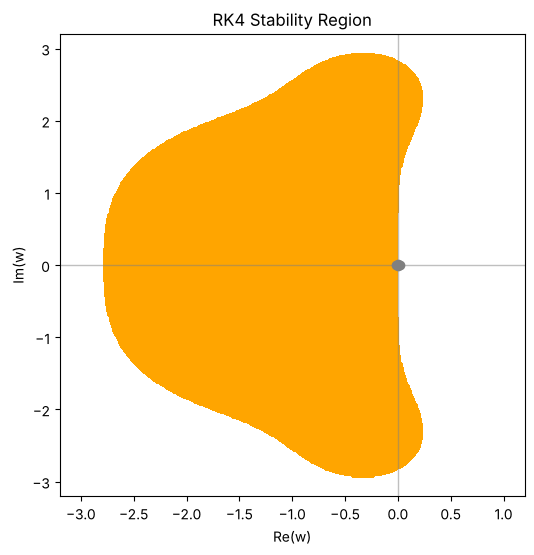

In [5]:
x, y = np.meshgrid(np.linspace(-3.2, 1.2, 401), np.linspace(-3.2, 3.2, 401)) # x = Re(w), y = Im(w)

dt_lam = x + 1j * y # w

amp = np.abs(1 + dt_lam + (1/2)*dt_lam**2 + (1/6)*dt_lam**3 + (1/24)*dt_lam**4)
stable = amp < 1

fig2 = plt.figure(figsize=(6, 6))
ax21 = fig2.add_subplot(111)

ax21.contourf(x, y, stable, levels=[0.5, 1.5], colors='ORANGE')
ax21.set_title('RK4 Stability Region')
ax21.set_xlabel('Re(w)')
ax21.set_ylabel('Im(w)')
ax21.axhline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)
ax21.axvline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)

import json
nominal = json.load(open('results/nominal.json'))
dt_test_ND = nominal['dt_nd'] # nondimensional, like the eigenvalues

# eigenvalues at the TLI state, where |lambda| is largest
eig_tli = np.linalg.eigvals(jacobian(tli_state(nominal['delta_v_kms'], nominal['phi_rad']), MU))
w_tli = dt_test_ND * eig_tli
print('lambda at TLI:', np.round(eig_tli, 1))
print('lambda * dt :', np.round(w_tli, 4))

ax21.scatter(w_tli.real, w_tli.imag, color='GREY', zorder=3)

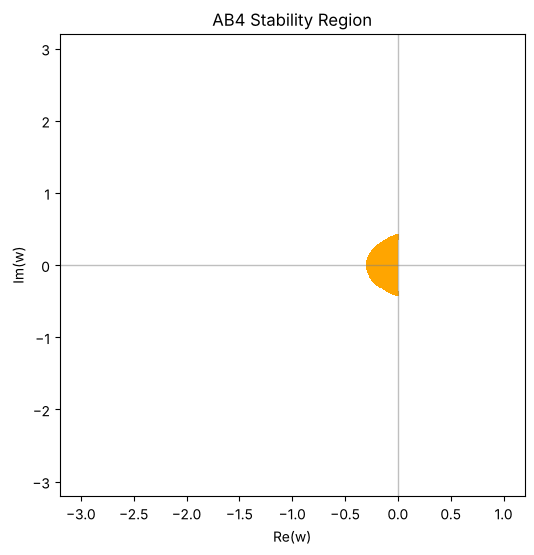

In [6]:
x, y = np.meshgrid(np.linspace(-3.2, 1.2, 401), np.linspace(-3.2, 3.2, 401)) # x = Re(w), y = Im(w)

dt_lam = x + 1j * y # w

ab4_coeffs = lambda w : [1, -(1+(55/24)*w), (59/24)*w, -(37/24)*w, (3/8)*w]

amp = np.array([[np.max(np.abs(np.roots(ab4_coeffs(w)))) for w in row] for row in dt_lam])

stable = amp < 1

fig2 = plt.figure(figsize=(6, 6))
ax21 = fig2.add_subplot(111)

ax21.contourf(x, y, stable, levels=[0.5, 1.5], colors='ORANGE')
ax21.set_title('AB4 Stability Region')
ax21.set_xlabel('Re(w)')
ax21.set_ylabel('Im(w)')
ax21.axhline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)
ax21.axvline(0, color="GREY", linestyle="-", linewidth=1, alpha=0.5)

#ax21.scatter(eigenvals.real, eigenvals.imag, color='GREY')

Comparing the stability regions: AB4 is the same order as RK4 and also explicit, but it is stable on the imaginary axis only up to $|\lambda\Delta t| \approx 0.43$, against $2\sqrt{2} \approx 2.83$ for RK4. At our study time step $|\lambda|\Delta t \approx 0.02$, so **both** would be stable here; AB4's smaller region is not by itself a reason to reject it. The deciding reason is that RK4 is a one-step method (see above): impulsive midcourse burns and partial steps for event location would force AB4 to restart its four-step history.

In [7]:
# INITIAL CONDITIONS: the retargeted nominal (gamma_EI = -6.52 deg), from scripts/retarget_nominal.py

delta_v = nominal['delta_v_kms'] # km/s
phi = nominal['phi_rad'] # rad

u_start_ND = tli_state(delta_v, phi)

# stop just before entry interface (t_EI = 1.740 nondimensional), so the whole run is a coast
t_f_ND = 1.7
t_f = t_f_ND*T

Self-convergence against a small $\Delta t$, to confirm the expected rate of $\Delta t^4$. This confirms the **rate** only; the checks that the answer is **correct** (exact two-body solution, JPL periodic orbit, Jacobi constant) are in `scripts/verify_*.py`.

The error is the norm of the full state difference. The largest $\Delta t$ in the original list ($t_f/2^{11} \approx 10^{-3}$) is outside the asymptotic range (the trajectory there is qualitatively wrong), so the list starts at $t_f/2^{12}$.

observed orders: [4.5  4.21 4.12 4.14]


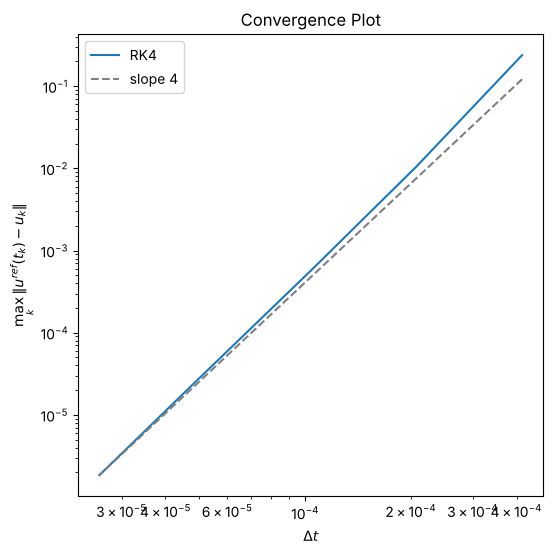

In [8]:
from Helpers.rk4 import rk4

dt_ref_ND = t_f_ND/2**17
dt_ref = dt_ref_ND * T

dt_list_ND = np.array([t_f_ND/2**12, t_f_ND/2**13, t_f_ND/2**14, t_f_ND/2**15, t_f_ND/2**16])
dt_list = dt_list_ND * T

u_ref_ND, times_ref_ND = rk4(f_spacecraft, u_start_ND, t_f_ND, dt_ref_ND)

def global_error(u, times, dt_ND):
    '''max over k of the norm of the full-state difference from the reference'''
    return np.linalg.norm(u - u_ref_ND[::(int(round(dt_ND/dt_ref_ND)))], axis=1).max()

error_list_ND = []

for dt_ND in dt_list_ND:
    u, times = rk4(f_spacecraft, u_start_ND, t_f_ND, dt_ND)
    error_list_ND.append(global_error(u, times, dt_ND))

fig4 = plt.figure(figsize=(6, 6))
ax41 = fig4.add_subplot(111)

ax41.set_title(f'Convergence Plot')
ax41.set_xlabel(r'$\Delta t$')
ax41.set_ylabel(r'$\max_k \| u^{ref}(t_k) - u_k \|$')
ax41.set_xscale('log')
ax41.set_yscale('log')

ax41.plot(dt_list_ND, error_list_ND, label='RK4')
ax41.plot(dt_list_ND, error_list_ND[-1] * (dt_list_ND / dt_list_ND[-1])**4, ls='--', color='GREY', label='slope 4')

ax41.legend()

error_list_ND = np.array(error_list_ND)
print('observed orders:', np.round(np.log2(error_list_ND[:-1]/error_list_ND[1:]), 2))